In [21]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA

# Notebook lives in rag/build-samples/, corpus in <root>/corpus/
ROOT = Path.cwd().resolve()
while not (ROOT / "corpus" / "chunks").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
CHUNKS_PATH = ROOT / "corpus" / "chunks" / "time_chunks.json"

chunks = json.loads(CHUNKS_PATH.read_text(encoding="utf-8"))
V = np.load(CHUNKS_PATH.with_suffix(".npy"))
meta = json.loads(CHUNKS_PATH.with_suffix(".meta.json").read_text(encoding="utf-8"))

# row i of V = chunk i of the JSON
assert V.shape[0] == len(chunks) and meta["ids"] == [c["id"] for c in chunks], "vectors do not match chunks - re-embed"
print(f"{V.shape[0]} chunks x {V.shape[1]} dims ({meta['model']})")

# per-chunk attributes used for colouring
first_date = {}
for c in chunks:
    first_date[c["youtubeId"]] = c["date"]
stream_ids = sorted(first_date, key=first_date.get)
stream_idx = np.array([stream_ids.index(c["youtubeId"]) for c in chunks])          # 0 = oldest stream
stream_end = {}
for c in chunks:
    stream_end[c["youtubeId"]] = max(stream_end.get(c["youtubeId"], 0), c["end"])
position = np.array([c["start"] / stream_end[c["youtubeId"]] for c in chunks])      # 0 = start of stream, 1 = end

917 chunks x 1024 dims (BAAI/bge-m3)


In [22]:
pca = PCA(n_components=50, random_state=0)
X = pca.fit_transform(V)     # X[:, 0], X[:, 1] = PC1, PC2

ev = pca.explained_variance_ratio_
cum = np.cumsum(ev)
print("explained variance, first 5 PCs:", np.round(ev[:5], 4))
print(f"PC1+PC2 = {ev[:2].sum():.1%} | 10 PCs = {cum[9]:.1%} | 50 PCs = {cum[49]:.1%}")

explained variance, first 5 PCs: [0.0524 0.0326 0.0267 0.023  0.0172]
PC1+PC2 = 8.5% | 10 PCs = 21.9% | 50 PCs = 50.0%


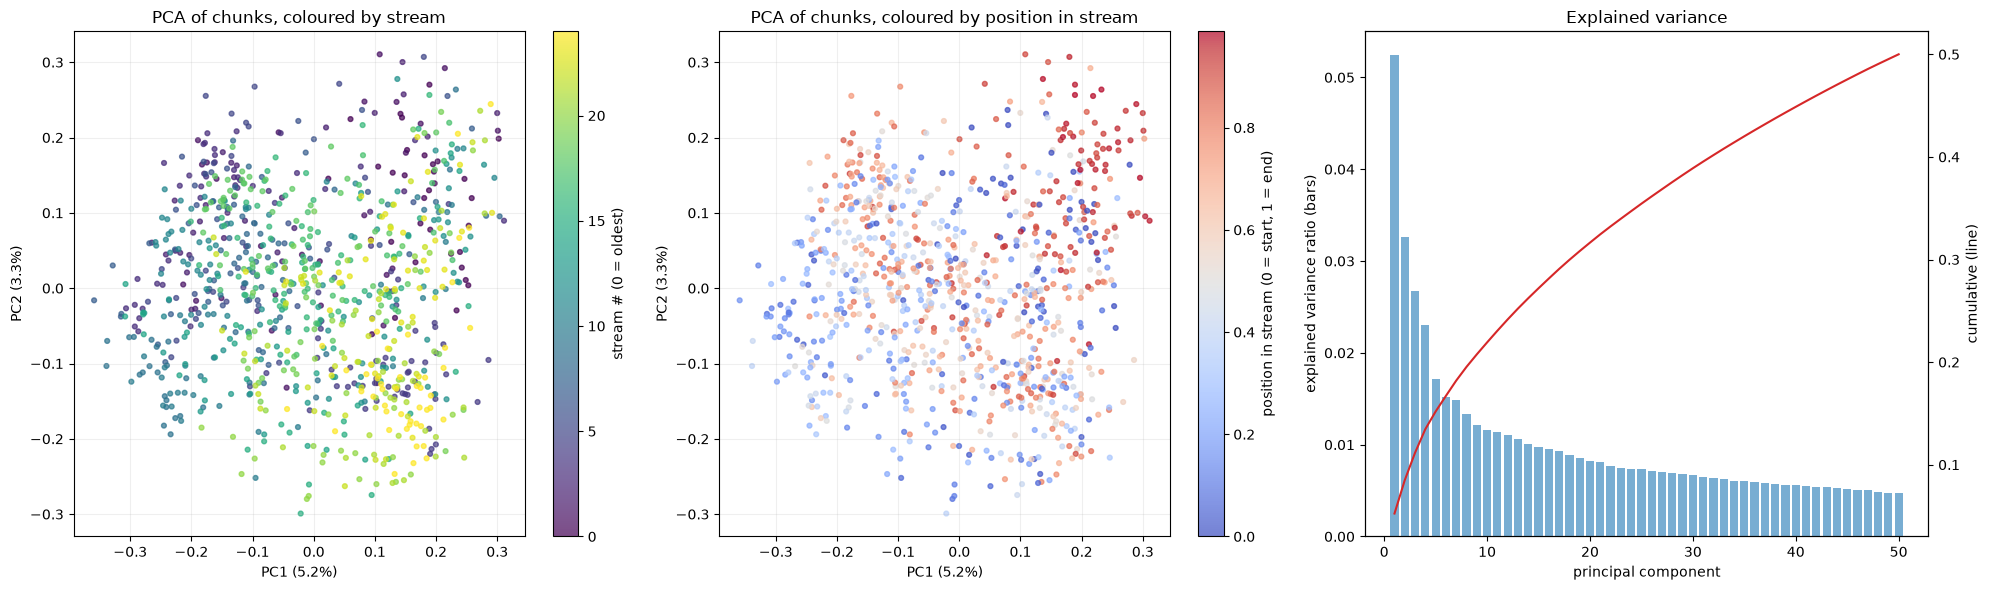

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1) which stream a chunk belongs to (colour = stream order in time)
sc = axes[0].scatter(X[:, 0], X[:, 1], c=stream_idx, cmap="viridis", s=12, alpha=0.7)
fig.colorbar(sc, ax=axes[0], label="stream # (0 = oldest)")
axes[0].set_title("PCA of chunks, coloured by stream")

# 2) where in the stream the chunk is (intro / outro boilerplate usually shows up as a blob)
sc = axes[1].scatter(X[:, 0], X[:, 1], c=position, cmap="coolwarm", s=12, alpha=0.7)
fig.colorbar(sc, ax=axes[1], label="position in stream (0 = start, 1 = end)")
axes[1].set_title("PCA of chunks, coloured by position in stream")

# 3) how many dimensions carry the variance
axes[2].bar(range(1, 51), ev, color="tab:blue", alpha=0.6)
axes[2].set_xlabel("principal component")
axes[2].set_ylabel("explained variance ratio (bars)")
twin = axes[2].twinx()
twin.plot(range(1, 51), cum, color="tab:red")
twin.set_ylabel("cumulative (line)")
axes[2].set_title("Explained variance")

for ax in axes[:2]:
    ax.set_xlabel(f"PC1 ({ev[0]:.1%})")
    ax.set_ylabel(f"PC2 ({ev[1]:.1%})")
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [24]:
import umap
from sklearn.manifold import trustworthiness

# cosine metric: bge-m3 vectors are compared by angle. random_state makes the layout reproducible
# (at the cost of single-threaded fitting, fine for ~1k points).
reducer = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, metric="cosine", random_state=42)
U = reducer.fit_transform(V)

# how well does each 2D map keep the true neighbourhoods? (1.0 = perfect, ~0.5 = random)
t_pca = trustworthiness(V, X[:, :2], n_neighbors=10, metric="cosine")
t_umap = trustworthiness(V, U, n_neighbors=10, metric="cosine")
print(f"trustworthiness (10 neighbours): PCA 2D = {t_pca:.3f} | UMAP 2D = {t_umap:.3f}")

S:\ai_projects\demo_26_RAG-vs-agent\rag\.venv\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
S:\ai_projects\demo_26_RAG-vs-agent\rag\.venv\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


trustworthiness (10 neighbours): PCA 2D = 0.762 | UMAP 2D = 0.918


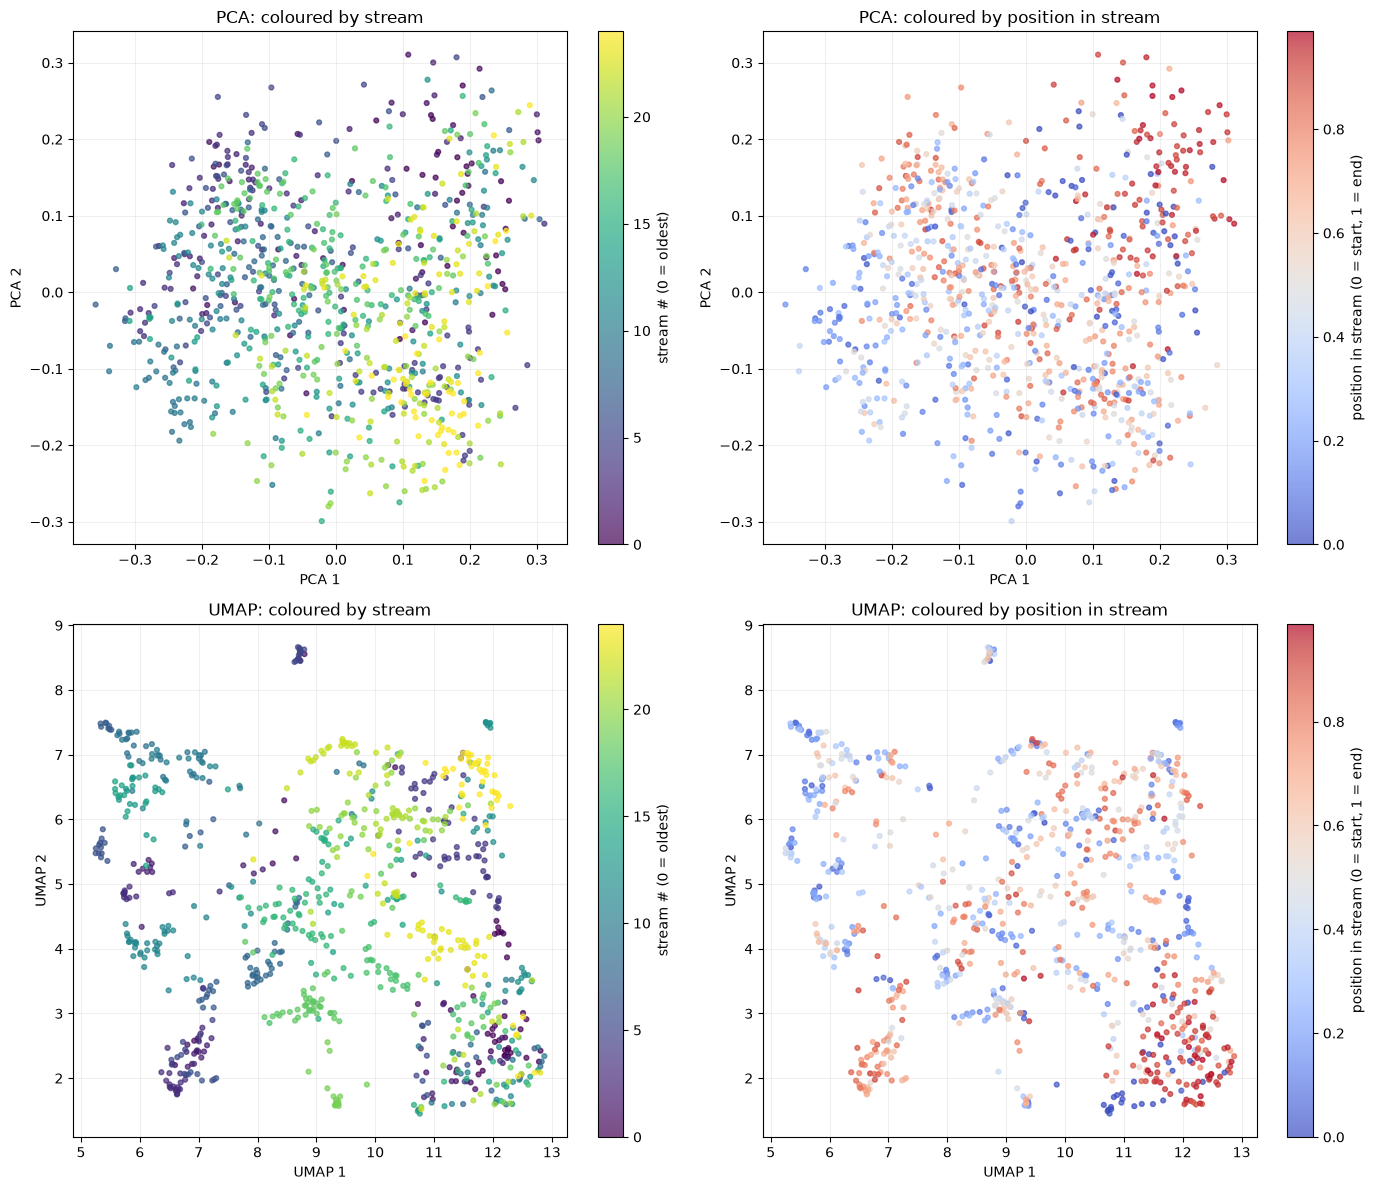

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

for row, (name, P) in enumerate([("PCA", X[:, :2]), ("UMAP", U)]):
    sc = axes[row, 0].scatter(P[:, 0], P[:, 1], c=stream_idx, cmap="viridis", s=12, alpha=0.7)
    fig.colorbar(sc, ax=axes[row, 0], label="stream # (0 = oldest)")
    axes[row, 0].set_title(f"{name}: coloured by stream")

    sc = axes[row, 1].scatter(P[:, 0], P[:, 1], c=position, cmap="coolwarm", s=12, alpha=0.7)
    fig.colorbar(sc, ax=axes[row, 1], label="position in stream (0 = start, 1 = end)")
    axes[row, 1].set_title(f"{name}: coloured by position in stream")

    for ax in axes[row]:
        ax.set_xlabel(f"{name} 1")
        ax.set_ylabel(f"{name} 2")
        ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## HDBSCAN clustering

In [26]:
# ---- Reduced space for clustering: UMAP 1024 -> 10 dims (the 2D map U above is only for plotting) ----
# min_dist=0.0 packs similar points tightly, which is what density-based clustering wants.
N_DIMS = 10
R = umap.UMAP(n_components=N_DIMS, n_neighbors=15, min_dist=0.0, metric="cosine", random_state=42).fit_transform(V)
print("reduced:", R.shape)

S:\ai_projects\demo_26_RAG-vs-agent\rag\.venv\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
S:\ai_projects\demo_26_RAG-vs-agent\rag\.venv\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


reduced: (917, 10)


In [27]:
from itertools import product
from sklearn.cluster import HDBSCAN
from sklearn.metrics import silhouette_score

# HDBSCAN configs to compare. In the reduced space euclidean distance is the right metric.
#   min_cluster_size  - smallest group that may count as a cluster (in chunks)
#   min_samples       - how conservative: higher -> more points are declared noise
#   selection         - "eom": fewer, bigger clusters | "leaf": many small, fine-grained clusters
GRID = list(product([5, 10, 20], [1, 5], ["eom", "leaf"]))   # (min_cluster_size, min_samples, selection)

runs = []   # one dict per config; labels: -1 = noise
for mcs, ms, sel in GRID:
    labels = HDBSCAN(min_cluster_size=mcs, min_samples=ms, cluster_selection_method=sel).fit_predict(R)
    mask = labels >= 0
    sizes = np.bincount(labels[mask]) if mask.any() else np.array([0])
    n_clusters = len(sizes) if mask.any() else 0
    ok = n_clusters >= 2
    runs.append({
        "mcs": mcs, "ms": ms, "sel": sel, "labels": labels, "n_clusters": n_clusters,
        "noise": 1 - mask.mean(), "median": int(np.median(sizes)), "max": int(sizes.max()),
        "sil_red": silhouette_score(R[mask], labels[mask]) if ok else float("nan"),                       # reduced space
        "sil_cos": silhouette_score(V[mask], labels[mask], metric="cosine") if ok else float("nan"),       # original space
    })

print(f"{'min_cl_size':>11} {'min_samples':>11} {'select':>6} | {'clusters':>8} {'noise':>6} {'median':>6} {'max':>4} | {'silh(red)':>9} {'silh(cos)':>9}")
for r in runs:
    print(f"{r['mcs']:>11} {r['ms']:>11} {r['sel']:>6} | {r['n_clusters']:>8} {r['noise']:>6.0%} {r['median']:>6} {r['max']:>4} | {r['sil_red']:>9.3f} {r['sil_cos']:>9.3f}")

S:\ai_projects\demo_26_RAG-vs-agent\rag\.venv\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
S:\ai_projects\demo_26_RAG-vs-agent\rag\.venv\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
S:\ai_projects\demo_26_RAG-vs-agent\rag\.venv\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
S:\ai_projects\demo_26_RAG-vs-agent\rag\.venv\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence th

min_cl_size min_samples select | clusters  noise median  max | silh(red) silh(cos)
          5           1    eom |       71    15%      9   34 |     0.502     0.082
          5           1   leaf |       80    22%      8   27 |     0.513     0.088
          5           5    eom |       41    18%     13   85 |     0.485     0.071
          5           5   leaf |       55    34%      9   29 |     0.559     0.099
         10           1    eom |       30    14%     19   95 |     0.480     0.056
         10           1   leaf |       38    19%     18   43 |     0.514     0.073
         10           5    eom |       28    19%     20   95 |     0.516     0.069
         10           5   leaf |       32    24%     20   40 |     0.519     0.076
         20           1    eom |       15    13%     43  164 |     0.480     0.061
         20           1   leaf |       18    18%     36   97 |     0.470     0.059
         20           5    eom |       10    10%     55  263 |     0.319     0.048
    

S:\ai_projects\demo_26_RAG-vs-agent\rag\.venv\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


S:\ai_projects\demo_26_RAG-vs-agent\rag\.venv\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
S:\ai_projects\demo_26_RAG-vs-agent\rag\.venv\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
S:\ai_projects\demo_26_RAG-vs-agent\rag\.venv\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization a

dims= 5  trustworthiness(10) = 0.945


S:\ai_projects\demo_26_RAG-vs-agent\rag\.venv\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
S:\ai_projects\demo_26_RAG-vs-agent\rag\.venv\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
S:\ai_projects\demo_26_RAG-vs-agent\rag\.venv\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization a

dims=10  trustworthiness(10) = 0.947


S:\ai_projects\demo_26_RAG-vs-agent\rag\.venv\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
S:\ai_projects\demo_26_RAG-vs-agent\rag\.venv\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
S:\ai_projects\demo_26_RAG-vs-agent\rag\.venv\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization a

dims=20  trustworthiness(10) = 0.946


S:\ai_projects\demo_26_RAG-vs-agent\rag\.venv\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
S:\ai_projects\demo_26_RAG-vs-agent\rag\.venv\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
S:\ai_projects\demo_26_RAG-vs-agent\rag\.venv\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization a

dims=30  trustworthiness(10) = 0.948


S:\ai_projects\demo_26_RAG-vs-agent\rag\.venv\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
S:\ai_projects\demo_26_RAG-vs-agent\rag\.venv\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
S:\ai_projects\demo_26_RAG-vs-agent\rag\.venv\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
S:\ai_projects\demo_26_RAG-vs-agent\rag\.venv\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence th


58 of 96 configs satisfy the constraints. Top 10 by stability:
dims min_cl_size min_samples select | clusters  noise max share | stability
   5           5          10    eom |     21.0    25%       18% |     0.978
   5          10          10    eom |     19.3    25%       18% |     0.976
   5          20           5    eom |     15.0    17%       18% |     0.968
   5          10           5    eom |     23.0    15%       18% |     0.947
   5          20           1    eom |     16.0    13%       18% |     0.944
   5          15           1    eom |     21.7    10%       18% |     0.941
   5          15           5    eom |     20.3    15%       18% |     0.941
  10           5          10    eom |     18.0    23%       20% |     0.941
   5          20          10   leaf |     13.0    29%       17% |     0.935
  10          10          10    eom |     17.3    22%       20% |     0.934


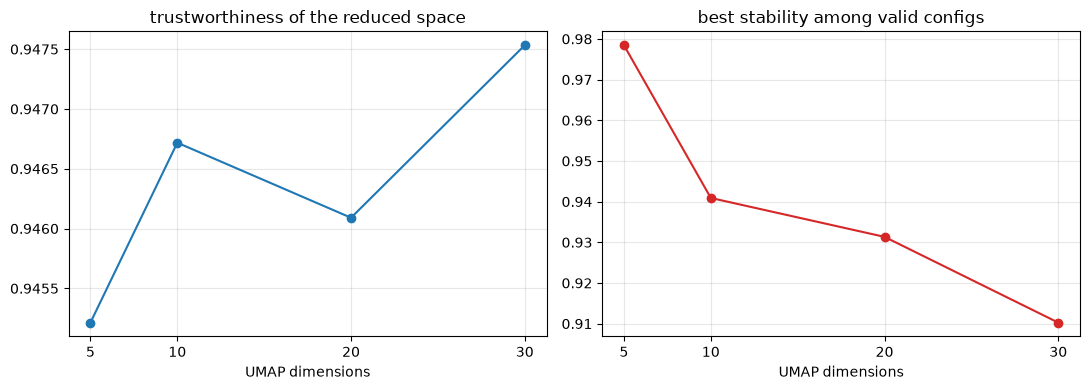

BEST: UMAP dims=5, min_cluster_size=5, min_samples=10, selection=eom -> 21 clusters, noise 25%, stability 0.978


In [28]:
# ---- Hyperparameter search for HDBSCAN: UMAP dimensions x HDBSCAN settings, scored on stability ----
# For every UMAP dimensionality we fit UMAP with several seeds, cluster each result with every HDBSCAN config and
# measure STABILITY = mean pairwise adjusted Rand index between the clusterings from different seeds, computed on
# chunks that are clustered (not noise) in both runs. 1.0 = same groups every time, ~0 = unrelated.
# Stability alone would favour a few huge clusters, so a config is only eligible if it also satisfies the constraints.
from sklearn.metrics import adjusted_rand_score

SWEEP_DIMS = [5, 10, 20, 30]
SEEDS = [0, 1, 2]
HDB_GRID = list(product([5, 10, 15, 20], [1, 5, 10], ["eom", "leaf"]))   # (min_cluster_size, min_samples, selection)

MAX_NOISE = 0.30                # at most 30% of chunks may be noise
CLUSTERS_RANGE = (10, 60)       # useful number of clusters for sampling
MAX_CLUSTER_SHARE = 0.25        # no cluster may hold more than 25% of all chunks


def pair_ari(a, b):
    m = (a >= 0) & (b >= 0)
    return adjusted_rand_score(a[m], b[m]) if len(set(a[m])) > 1 and len(set(b[m])) > 1 else 0.0


# 1) UMAP for each (dims, seed); trustworthiness of the reduced space vs the original vectors
reductions, trust = {}, {}
for d in SWEEP_DIMS:
    for seed in SEEDS:
        reductions[(d, seed)] = umap.UMAP(n_components=d, n_neighbors=15, min_dist=0.0, metric="cosine",
                                          random_state=seed).fit_transform(V)
    trust[d] = trustworthiness(V, reductions[(d, SEEDS[0])], n_neighbors=10, metric="cosine")
    print(f"dims={d:>2}  trustworthiness(10) = {trust[d]:.3f}")

# 2) HDBSCAN for every config on every reduction, then compare seeds
sweep = []
for d in SWEEP_DIMS:
    for mcs, ms, sel in HDB_GRID:
        labs = [HDBSCAN(min_cluster_size=mcs, min_samples=ms, cluster_selection_method=sel).fit_predict(reductions[(d, s)])
                for s in SEEDS]
        sizes = [np.bincount(l[l >= 0]) if (l >= 0).any() else np.array([0]) for l in labs]
        row = {
            "dims": d, "mcs": mcs, "ms": ms, "sel": sel, "labels": labs[0],
            "n_clusters": float(np.mean([len(s) for s in sizes])),
            "noise": float(np.mean([(l < 0).mean() for l in labs])),
            "max_share": float(max(s.max() for s in sizes) / len(V)),
            "stability": float(np.mean([pair_ari(labs[i], labs[j]) for i in range(len(labs)) for j in range(i + 1, len(labs))])),
        }
        row["valid"] = (row["noise"] <= MAX_NOISE and CLUSTERS_RANGE[0] <= row["n_clusters"] <= CLUSTERS_RANGE[1]
                        and row["max_share"] <= MAX_CLUSTER_SHARE)
        sweep.append(row)

ranked = sorted((r for r in sweep if r["valid"]), key=lambda r: -r["stability"])
print(f"\n{len(ranked)} of {len(sweep)} configs satisfy the constraints. Top 10 by stability:")
print(f"{'dims':>4} {'min_cl_size':>11} {'min_samples':>11} {'select':>6} | {'clusters':>8} {'noise':>6} {'max share':>9} | {'stability':>9}")
for r in ranked[:10]:
    print(f"{r['dims']:>4} {r['mcs']:>11} {r['ms']:>11} {r['sel']:>6} | {r['n_clusters']:>8.1f} {r['noise']:>6.0%} {r['max_share']:>9.0%} | {r['stability']:>9.3f}")

# 3) does the number of UMAP dimensions matter?
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(SWEEP_DIMS, [trust[d] for d in SWEEP_DIMS], "o-")
axes[0].set_title("trustworthiness of the reduced space"); axes[0].set_xlabel("UMAP dimensions")
best_per_dim = [max((r["stability"] for r in ranked if r["dims"] == d), default=np.nan) for d in SWEEP_DIMS]
axes[1].plot(SWEEP_DIMS, best_per_dim, "o-", color="tab:red")
axes[1].set_title("best stability among valid configs"); axes[1].set_xlabel("UMAP dimensions")
for ax in axes:
    ax.set_xticks(SWEEP_DIMS); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 4) winners, used by the chart below
top_runs = ranked[:8]
assert top_runs, "no config satisfies the constraints - relax MAX_NOISE / CLUSTERS_RANGE / MAX_CLUSTER_SHARE"
best = top_runs[0]
print(f"BEST: UMAP dims={best['dims']}, min_cluster_size={best['mcs']}, min_samples={best['ms']}, "
      f"selection={best['sel']} -> {best['n_clusters']:.0f} clusters, noise {best['noise']:.0%}, stability {best['stability']:.3f}")

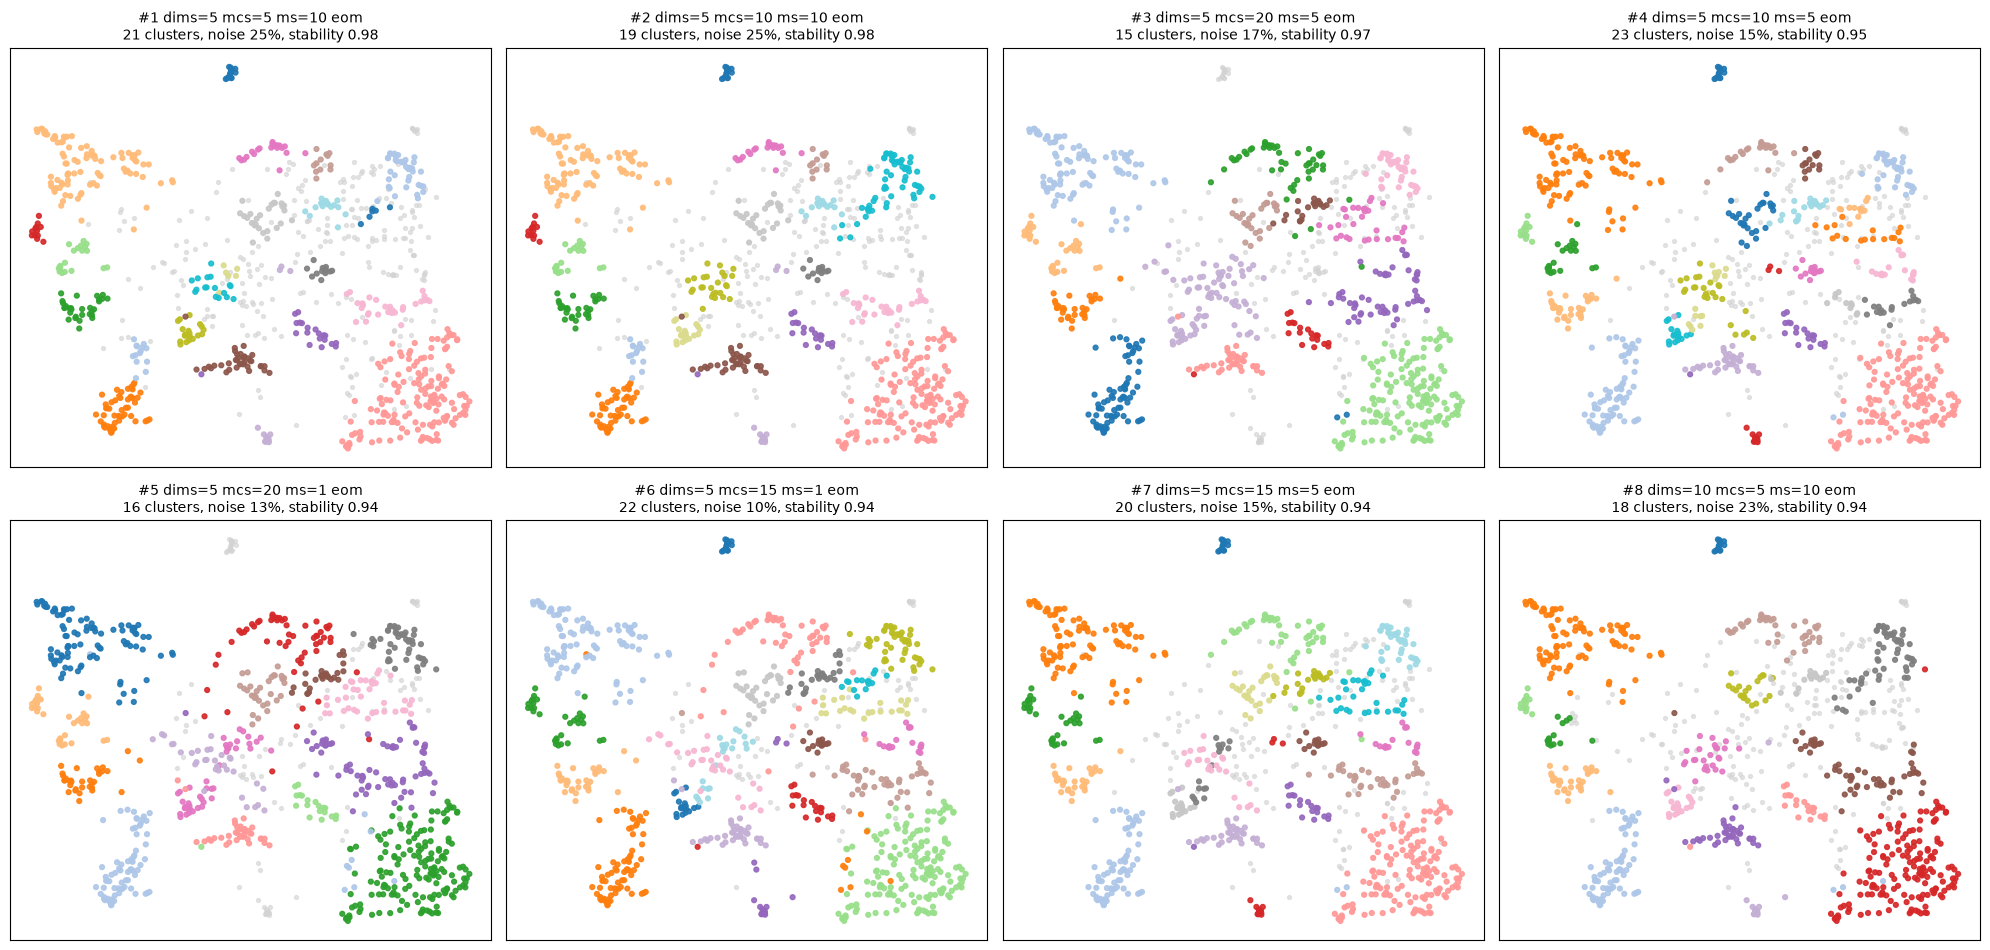

In [29]:
# ---- UMAP-2D map coloured by the clusters of the best configs from the search (grey = noise) ----
ncols = 4
nrows = int(np.ceil(len(top_runs) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.8 * nrows), squeeze=False)
palette = plt.get_cmap("tab20")

for rank, (ax, r) in enumerate(zip(axes.ravel(), top_runs), 1):
    lab = r["labels"]
    noise = lab < 0
    ax.scatter(U[noise, 0], U[noise, 1], c="lightgrey", s=8, alpha=0.6)
    ax.scatter(U[~noise, 0], U[~noise, 1], c=[palette(l % 20) for l in lab[~noise]], s=12, alpha=0.9)
    ax.set_title(f"#{rank} dims={r['dims']} mcs={r['mcs']} ms={r['ms']} {r['sel']}\n"
                 f"{r['n_clusters']:.0f} clusters, noise {r['noise']:.0%}, stability {r['stability']:.2f}", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
for ax in axes.ravel()[len(top_runs):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Cluster report

One row per cluster of the best config from the search above: size, cohesion, where it comes from, keywords (c-TF-IDF), and the most typical chunks.

In [30]:
# ---- Cluster statistics for the best config ----
from collections import Counter

labels = best["labels"]                                  # -1 = noise
cluster_ids = sorted(set(labels[labels >= 0]))
print(f"config: UMAP dims={best['dims']}, min_cluster_size={best['mcs']}, min_samples={best['ms']}, {best['sel']}")
print(f"{len(cluster_ids)} clusters, noise: {(labels < 0).sum()} of {len(labels)} chunks")

streams = np.array([c["youtubeId"] for c in chunks])
dates = np.array([c["date"] for c in chunks])

# V is L2-normalised, so a dot product is the cosine similarity
centroids = {}
for k in cluster_ids:
    cen = V[labels == k].mean(axis=0)
    centroids[k] = cen / np.linalg.norm(cen)

report = {}
for k in cluster_ids:
    idx = np.where(labels == k)[0]
    sims = V[idx] @ centroids[k]
    by_stream = Counter(streams[idx])
    other = {j: float(centroids[k] @ centroids[j]) for j in cluster_ids if j != k}
    nearest = max(other, key=other.get)
    report[k] = {
        "idx": idx,
        "size": len(idx),
        "cohesion": float(sims.mean()),                      # mean cosine similarity to the centroid
        "n_streams": len(by_stream),
        "top_stream_share": max(by_stream.values()) / len(idx),
        "date_from": min(dates[idx]), "date_to": max(dates[idx]),   # ISO dates sort as strings
        "pos_mean": float(position[idx].mean()),             # 0 = start of stream, 1 = end
        "nearest": nearest, "nearest_sim": other[nearest],   # closest other cluster (merge candidate if very high)
        "central": idx[np.argsort(-sims)[:2]],               # 2 chunks closest to the centroid
        "edge": idx[np.argmin(sims)],                        # the least typical member
    }

config: UMAP dims=5, min_cluster_size=5, min_samples=10, eom
22 clusters, noise: 245 of 917 chunks


In [33]:
# ---- Keywords: class-based TF-IDF (every cluster = one document; noise is an extra "class" for contrast) ----
# A word scores high if it is frequent in this cluster and rare in the others, so words used everywhere
# (pronouns, conjunctions, ...) get a score near zero without being listed by hand.
import re
from sklearn.feature_extraction.text import CountVectorizer

STOPWORDS_PATH = ROOT / "rag" / "build-samples" / "terms" / "stopwords_uk.txt"
UK_STOP = {w.strip() for w in STOPWORDS_PATH.read_text(encoding="utf-8").splitlines()
           if w.strip() and not w.startswith("#")}
UK_STOP = {w for w in UK_STOP if len(w) >= 3}      # the tokenizer below ignores shorter tokens anyway

TOP_N = 8
MIN_COUNT = 3                                       # a keyword must occur at least 3 times in its cluster

docs = [" ".join(chunks[i]["text"] for i in report[k]["idx"]) for k in cluster_ids]
docs.append(" ".join(chunks[i]["text"] for i in np.where(labels < 0)[0]))   # noise class

cv = CountVectorizer(
    preprocessor=lambda s: s.lower().replace("\u02bc", "'").replace("\u2019", "'"),   # typographic -> plain apostrophe
    token_pattern=r"(?u)\b[^\W\d_][\w'-]{2,}\b",    # words of >= 3 chars that start with a letter
    stop_words=sorted(UK_STOP),
    ngram_range=(1, 2),
)
counts = cv.fit_transform(docs).toarray().astype(float)                      # (classes, terms)
vocab = np.array(cv.get_feature_names_out())

tf = counts / counts.sum(axis=1, keepdims=True)
avg_words = counts.sum(axis=1).mean()
idf = np.log(avg_words / counts.sum(axis=0) + 1)                              # BERTopic-style idf over classes
ctfidf = tf * idf

for row, k in enumerate(cluster_ids):
    score = np.where(counts[row] >= MIN_COUNT, ctfidf[row], 0)
    report[k]["keywords"] = list(vocab[np.argsort(-score)[:TOP_N]])

# boilerplate heuristics: a hint to look at the cluster, not a verdict
FAREWELL_PATH = ROOT / "rag" / "build-samples" / "terms" / "farewell_words_uk.txt"
FAREWELL = [w.strip() for w in FAREWELL_PATH.read_text(encoding="utf-8").splitlines()
            if w.strip() and not w.startswith("#")]
for k, r in report.items():
    r["flags"] = [f for f, on in [
        ("outro?", r["pos_mean"] >= 0.85),
        ("intro?", r["pos_mean"] <= 0.12),
        ("one-stream", r["top_stream_share"] >= 0.8),
        ("farewell words", sum(any(o in kw for o in FAREWELL) for kw in r["keywords"]) >= 2),
    ] if on]

print(f"{'id':>3} {'size':>4} {'cohes':>5} {'streams':>7} {'top%':>5} {'dates':>23} {'pos':>4} {'nearest':>12}  keywords")
for k, r in report.items():
    dates_txt = f"{r['date_from'][2:]}..{r['date_to'][2:]}"
    print(f"{k:>3} {r['size']:>4} {r['cohesion']:>5.2f} {r['n_streams']:>7} {r['top_stream_share']:>5.0%} {dates_txt:>23} "
          f"{r['pos_mean']:>4.2f} {r['nearest']:>4}({r['nearest_sim']:.2f})  {', '.join(r['keywords'][:6])}"
          + (f"   [{', '.join(r['flags'])}]" if r["flags"] else ""))

 id size cohes streams  top%                   dates  pos      nearest  keywords
  0   17  0.82       2   82%      26-05-23..26-06-20 0.34    3(0.85)  pwa, застосунок, скажем, сервіс, ios, працює   [one-stream]
  1   14  0.83       5   64%      26-06-06..26-08-01 0.61    2(0.89)  next, react, ssr, доповідь, прям, штука
  2   53  0.80       5   42%      26-05-23..26-06-27 0.73   18(0.90)  тепер, бачимо, штука, речі, компонент, окей
  3   90  0.78       6   29%      26-07-04..26-08-22 0.38    5(0.90)  наприклад, звісно, якісь, токен, пароль, зловмисник
  4   30  0.81       2   97%      26-05-30..26-08-01 0.44    5(0.90)  інше, наприклад, цілому, зробити, історія, пропси   [one-stream]
  5   21  0.81       3   57%      26-05-30..26-08-22 0.20    3(0.90)  дані, метод, ліміти, контекст, валідатор, websocket
  6   12  0.83       1  100%      26-06-27..26-06-27 0.25    5(0.86)  медіа, з'єднання, пакети, сервер, udp, клієнта   [one-stream]
  7  154  0.78      25   15%      26-05-16..26-10-31 0

In [34]:
# ---- Typical chunks of every cluster: 2 closest to the centroid + the least typical member ----
def show(i, tag, n=380):
    c = chunks[i]
    txt = c["text"][:n] + ("..." if len(c["text"]) > n else "")
    print(f"  [{tag}] {c['date']} {c['start_tc']} ({c['tokens']} tok) {c['url']}?t={c['start']}\n      {txt}")

for k, r in report.items():
    flags = f"  [{', '.join(r['flags'])}]" if r["flags"] else ""
    print(f"\n=== cluster {k}: {r['size']} chunks, {r['n_streams']} streams, cohesion {r['cohesion']:.2f}{flags}")
    print("    keywords:", ", ".join(r["keywords"]))
    for i in r["central"]:
        show(i, "central")
    show(r["edge"], "edge   ")


=== cluster 0: 17 chunks, 2 streams, cohesion 0.82  [one-stream]
    keywords: pwa, застосунок, скажем, сервіс, ios, працює, воркер, сервіс воркер
  [central] 2026-06-20 00:27:02 (828 tok) https://youtu.be/RJ9xqAfUl6M?t=1622
      там браузера зробили так, що всі сторінки мають закритися, а потім, коли всі відкриваються, то новий сервіс воркер запускається. Але є команди, які можна, чітко вказати, що не чекай активації, не чекай, коли всі закриються, активуйся. потрібно тоді розуміти, що новий сервіс воркер може активуватись, сторінка буде відкрита, якщо версії коду несумісні, то в цих користувачів можут...
  [central] 2026-06-20 00:32:49 (791 tok) https://youtu.be/RJ9xqAfUl6M?t=1969
      Щас ми відкриємо. Ось. Давайте видалимо, uninstall зробимо, uninstall. Все, нема. Тепер давайте відкриємо. А, ось віконце, яке ми самі зробили. Тобто, якщо застосунок не встановлений, ми можемо відслідкувати подію, що ми можемо його встановлювати. Ось, можемо показати користувачу якусь. галочку чи п

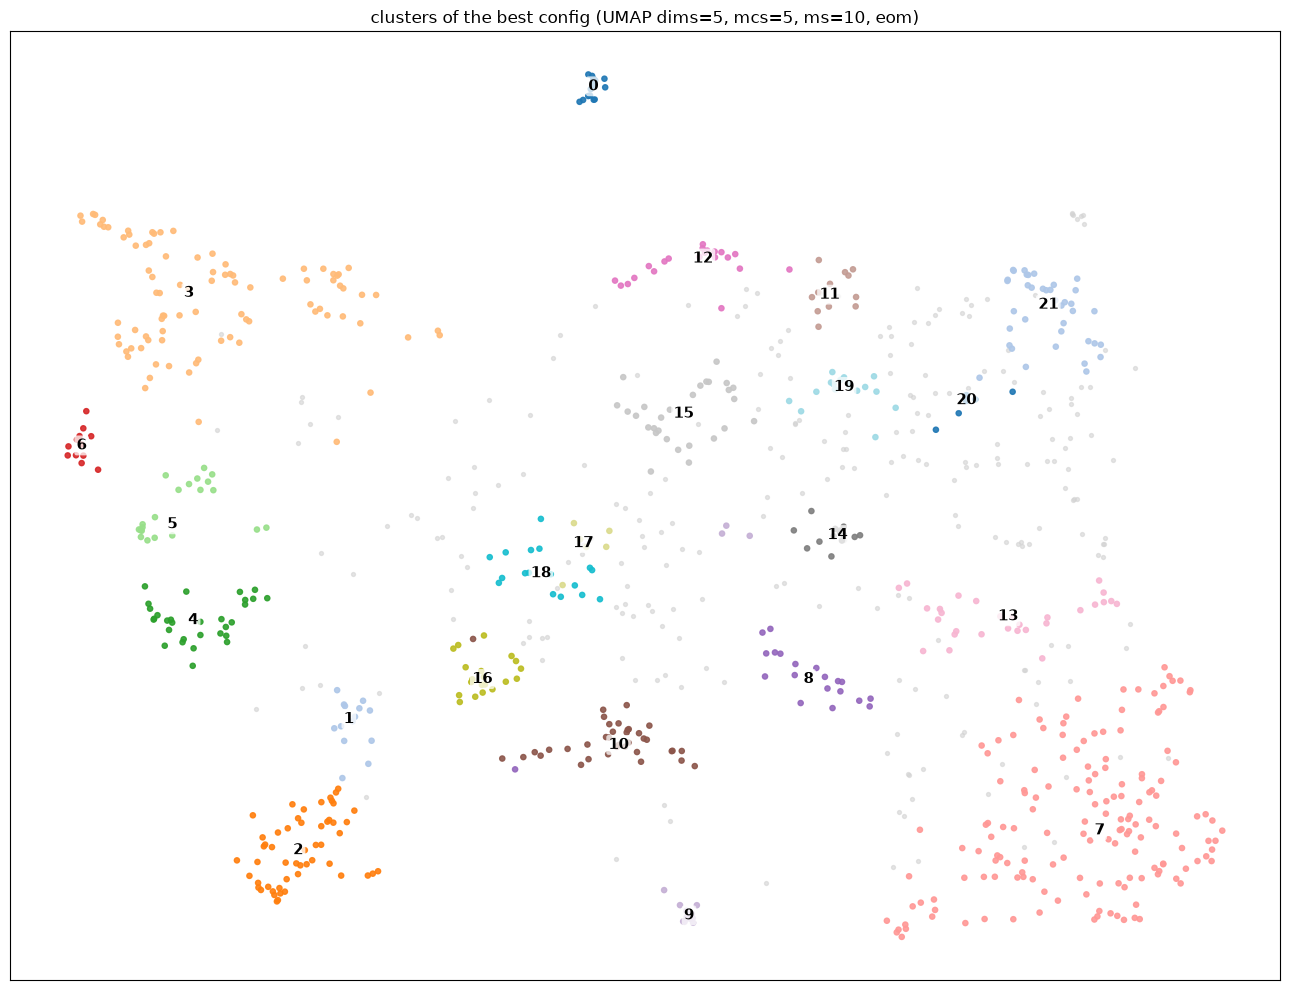

In [35]:
# ---- Map with cluster numbers (grey = noise) ----
fig, ax = plt.subplots(figsize=(13, 10))
palette = plt.get_cmap("tab20")
noise = labels < 0
ax.scatter(U[noise, 0], U[noise, 1], c="lightgrey", s=8, alpha=0.6, label="noise")
ax.scatter(U[~noise, 0], U[~noise, 1], c=[palette(l % 20) for l in labels[~noise]], s=14, alpha=0.9)
for k in cluster_ids:
    cx, cy = np.median(U[labels == k], axis=0)
    ax.text(cx, cy, str(k), fontsize=11, weight="bold", ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.75))
ax.set_title(f"clusters of the best config (UMAP dims={best['dims']}, mcs={best['mcs']}, ms={best['ms']}, {best['sel']})")
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

In [36]:
# ---- Save the clustering result for the sampling step ----
CLUSTERS_PATH = CHUNKS_PATH.with_name("clusters.json")

ids = [c["id"] for c in chunks]
sim_matrix = np.array([[float(centroids[a] @ centroids[b]) for b in cluster_ids] for a in cluster_ids])

out = {
    "config": {
        "embedding_model": meta["model"], "umap_dims": best["dims"], "umap_seed": SEEDS[0],
        "min_cluster_size": best["mcs"], "min_samples": best["ms"], "selection": best["sel"],
        "stability": round(best["stability"], 4),
    },
    "n_chunks": len(chunks),
    "labels": {cid: int(l) for cid, l in zip(ids, labels)},          # chunk id -> cluster id (-1 = noise)
    "clusters": {
        str(k): {
            "size": r["size"], "cohesion": round(r["cohesion"], 4),
            "n_streams": r["n_streams"], "top_stream_share": round(r["top_stream_share"], 4),
            "date_from": r["date_from"], "date_to": r["date_to"], "pos_mean": round(r["pos_mean"], 4),
            "keywords": r["keywords"], "flags": r["flags"],
            "central": [ids[i] for i in r["central"]], "edge": ids[r["edge"]],
            "nearest": int(r["nearest"]), "nearest_sim": round(r["nearest_sim"], 4),
        }
        for k, r in report.items()
    },
    # cosine similarity between cluster centroids: "similar clusters" = high value, "different" = low
    "centroid_similarity": {"cluster_ids": [int(k) for k in cluster_ids], "matrix": np.round(sim_matrix, 4).tolist()},
}
CLUSTERS_PATH.write_text(json.dumps(out, ensure_ascii=False, indent=1), encoding="utf-8")

# reload and verify the file lines up with time_chunks.json
saved = json.loads(CLUSTERS_PATH.read_text(encoding="utf-8"))
assert list(saved["labels"]) == ids, "labels do not follow the chunk order"
n_clustered = sum(1 for v in saved["labels"].values() if v >= 0)
print(f"{CLUSTERS_PATH}: {len(saved['labels'])} chunks ({n_clustered} clustered, {len(saved['labels']) - n_clustered} noise), "
      f"{len(saved['clusters'])} clusters")

S:\ai_projects\demo_26_RAG-vs-agent\corpus\chunks\clusters.json: 917 chunks (672 clustered, 245 noise), 22 clusters
